# A portrait across three faces of a folded cube

The goal: fold a ChArUco board into a cube, photograph it from one spot, and compute the flat sheet that, once folded the same way, shows a picture from that spot as if the cube weren't there.

This notebook traces it for one photo: a 50 mm cube (Kunihiko Kasahara's seamless cube, folded from the 200 mm board) with Holbein's self-portrait across its three visible faces. No hand marking is needed: the three faces are the canvas, and they can be found from the markers.

The steps:

1. Find the markers and sort them into three faces.
2. Find where each face is on the sheet.
3. Measure how each face's paper really lands in the photo, including its bow.
4. Check that against the photo.
5. Lay the picture over the cube.
6. Compute the sheet: each point gets the picture's color at the place it lands in the photo.
7. Check the result in two independent ways, and from other viewpoints.
8. Print.

## Setup

In [1]:
import importlib, os, subprocess, sys

FOLDER = "fold-map"
if not os.path.exists("photo_map.py"):
    if not os.path.exists("folded-illusions"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/rath-hy/folded-illusions.git"], check=True)
    os.chdir(os.path.join("folded-illusions", FOLDER))
sys.path.insert(0, os.getcwd())

import numpy as np
import matplotlib.pyplot as plt
import cv2
import photo_map as pm

PHOTO = "charuco pics/holbein_cube.JPG"
PICTURE = "charuco pics/holbein_square.jpeg"
OUTPUT = "prints/cube_holbein_a4.pdf"
FOCAL_35MM = 51     # the lens's 35 mm equivalent, read from the photo's EXIF before it was stripped
SMOOTHING = 30      # of the spline that follows the paper's bow: section 3 shows why
BLEED_MM = 4        # how far the picture continues past each face's edge

board = pm.make_board()
photo = pm.load_photo(PHOTO)
picture = pm.load_photo(PICTURE)
print("photo", photo.shape[1], "x", photo.shape[0], " picture", picture.shape[1], "x", picture.shape[0])

COLORS = dict(top="#2ca02c", left="#1f77b4", right="#ff7f0e")
def small(image, width=1600):       # photos are shrunk for display only, to keep this notebook light
    h, w = image.shape[:2]
    return np.clip(cv2.resize(image, (width, round(h * width / w)), interpolation=cv2.INTER_AREA), 0, 1), width / w

photo 4032 x 3024  picture 250 x 250


## 1. Find the markers and sort them into faces

Every marker found says which part of the sheet that patch of paper is. Markers on one flat face should agree on one transform, a homography, the mapping a flat plane undergoes when photographed at an angle.

At first the markers shattered into many small groups. The paper is slightly bowed, so strict agreement (within 0.15 of a marker's side) splits a face apart. The cube has only three visible faces, so a looser tolerance of 0.8 is safe, and they come out cleanly.

160 markers, side 54 to 109 px, median 74 px
strict tolerance, group sizes: [39, 31, 15, 17, 10, 8, 10, 13, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
loose tolerance, group sizes:  [60, 58, 42]
top  : 42 markers
left : 60 markers
right: 58 markers


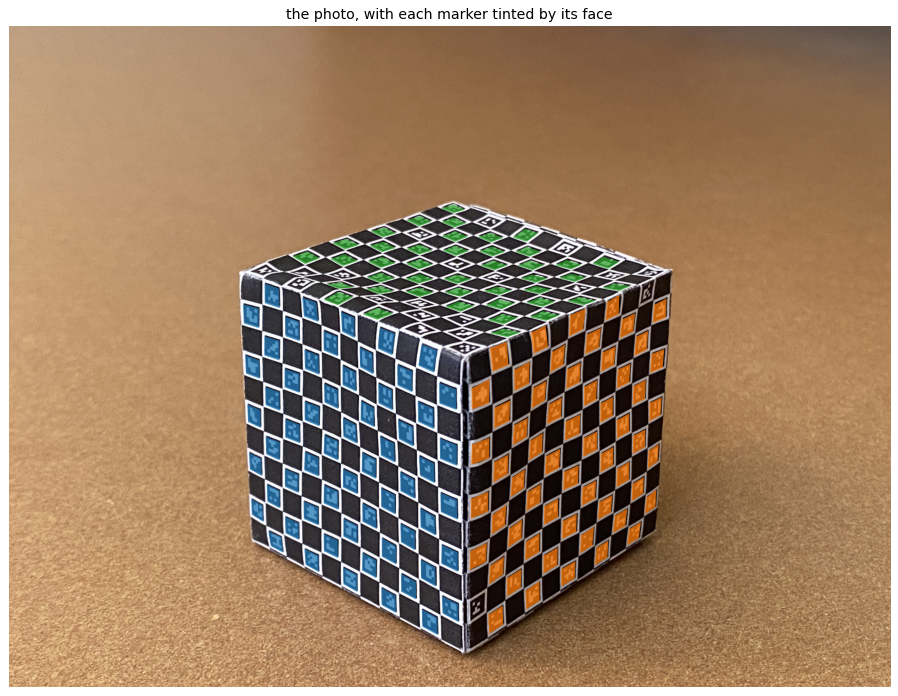

In [2]:
markers = pm.detect(photo, board)
sides = np.array([np.linalg.norm(c - np.roll(c, 1, 0), axis=1) for c in markers.values()])
print(f"{len(markers)} markers, side {sides.min():.0f} to {sides.max():.0f} px, median {np.median(sides):.0f} px")
print("strict tolerance, group sizes:", [len(i) for _, i in pm.fit_pieces(markers, board, "homography", 0.15)])
print("loose tolerance, group sizes: ", [len(i) for _, i in pm.fit_pieces(markers, board, "homography", 0.8)])

faces = pm.find_faces(markers, board)
for name, f in faces.items():
    print(f"{name:5}: {len(f['ids'])} markers")

view, s = small(photo)
fig, ax = plt.subplots(figsize=(11, 8.3))
ax.imshow(view)
for name, f in faces.items():
    for j in f["ids"]:
        ax.add_patch(plt.Polygon(markers[j] * s, fc=COLORS[name], ec="none", alpha=0.75))
ax.set_title("the photo, with each marker tinted by its face")
ax.axis("off"); fig.tight_layout(); plt.show()

## 2. Where the faces are on the sheet

Each marker's number says where it was printed, so the faces can be drawn on the flat sheet. They snap to the board's squares, and they have to come out square, which is a check on the assumption.

Three 50 mm squares, a quarter of the sheet's side, and they meet at one point: **the middle of the sheet is the corner of the cube facing the camera**. The fourth quadrant around the center, at the lower left, is out of sight: it's tucked into the groove of the cube's front edge.

top  : sheet x 100 to 150 mm, y 50 to 100 mm
left : sheet x 50 to 100 mm, y 50 to 100 mm
right: sheet x 100 to 150 mm, y 100 to 150 mm


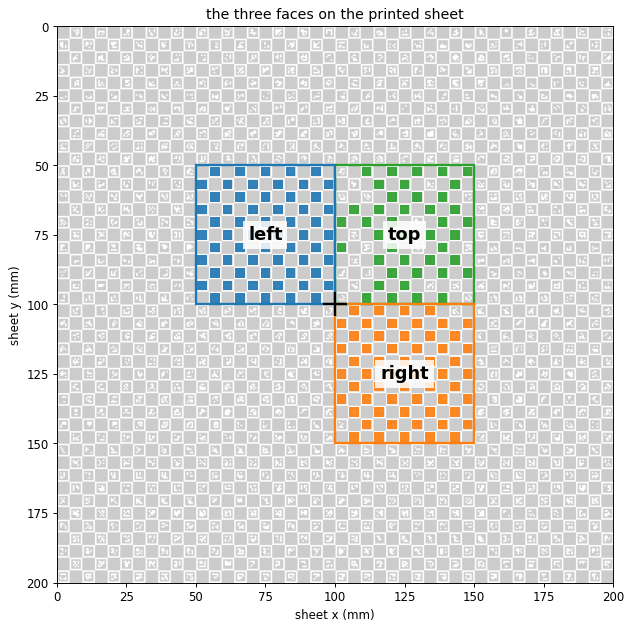

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.imshow(board.image, cmap="gray", extent=[0, 200, 200, 0], alpha=0.2)
for name, f in faces.items():
    for j in f["ids"]:
        ax.add_patch(plt.Polygon(board.corners[j], fc=COLORS[name], alpha=0.9))
    x0, y0, side = f["box"]
    ax.add_patch(plt.Rectangle((x0, y0), side, side, fill=False, ec=COLORS[name], lw=2))
    ax.text(x0 + side / 2, y0 + side / 2, name, ha="center", va="center", fontsize=15, weight="bold",
            bbox=dict(fc="white", ec="none", alpha=0.85))
    print(f"{name:5}: sheet x {x0:.0f} to {x0 + side:.0f} mm, y {y0:.0f} to {y0 + side:.0f} mm")
ax.plot([100], [100], "k+", ms=20, mew=2)
ax.set_xlabel("sheet x (mm)"); ax.set_ylabel("sheet y (mm)")
ax.set_title("the three faces on the printed sheet"); fig.tight_layout(); plt.show()

## 3. How each face's paper really lands in the photo

A flat cube face would need a homography and nothing else, but the left-hand plot below shows what that misses: errors in smooth swirls, not random noise, so the paper really is bowed. Those arrows are magnified 10×.

So each face gets a homography plus a **thin-plate spline**, a surface that bends smoothly through what the homography misses. I tried polynomials first, but the top face has a local dent near one corner that they couldn't follow. A spline can bend locally, and one setting, its smoothing, decides how closely it chases each point.

Too little smoothing would chase noise, so I don't judge it by how well it fits, only by how well it **predicts points it wasn't fitted to**. There are two tests:

- **Held out:** hide a random 10% of the points, fit the rest, and predict the hidden ones.
- **Rim:** fit the middle of the face and predict its outermost ring, which is harder, because it's extrapolation.

The points are the markers plus the checkerboard corners between them. Corners need no readable code, so they fill in where markers were missed, especially on the steep top face. Beyond the last measured point, the correction stays frozen.

error in photo pixels, rms / worst
                                   top                        left                       right
flat        held 13.2/ 30 rim 20.9/ 37  held  9.3/ 21 rim 12.9/ 23  held  7.2/ 22 rim  9.4/ 30
s = 3000    held  6.1/ 24 rim 13.1/ 29  held  4.1/ 16 rim  9.5/ 28  held  4.6/ 24 rim  8.9/ 36
s = 300     held  4.7/ 22 rim 10.1/ 29  held  2.6/ 12 rim  8.1/ 27  held  3.1/ 16 rim  7.9/ 31
s = 30      held  4.4/ 21 rim  9.4/ 28  held  2.1/  7 rim  7.4/ 25  held  2.5/ 13 rim  7.2/ 26
s = 3       held  4.5/ 17 rim  9.4/ 29  held  2.0/  5 rim  7.3/ 25  held  2.5/ 14 rim  7.1/ 24
s = 0       held  4.9/ 12 rim  9.6/ 29  held  1.8/  5 rim  7.6/ 25  held  2.7/ 15 rim  7.1/ 24

top  : 266 points (98% of its corners found), 16 px/mm, so held out 0.28 mm, rim 0.58 mm
left : 340 points (100% of its corners found), 22 px/mm, so held out 0.09 mm, rim 0.33 mm
right: 332 points (100% of its corners found), 21 px/mm, so held out 0.12 mm, rim 0.35 mm


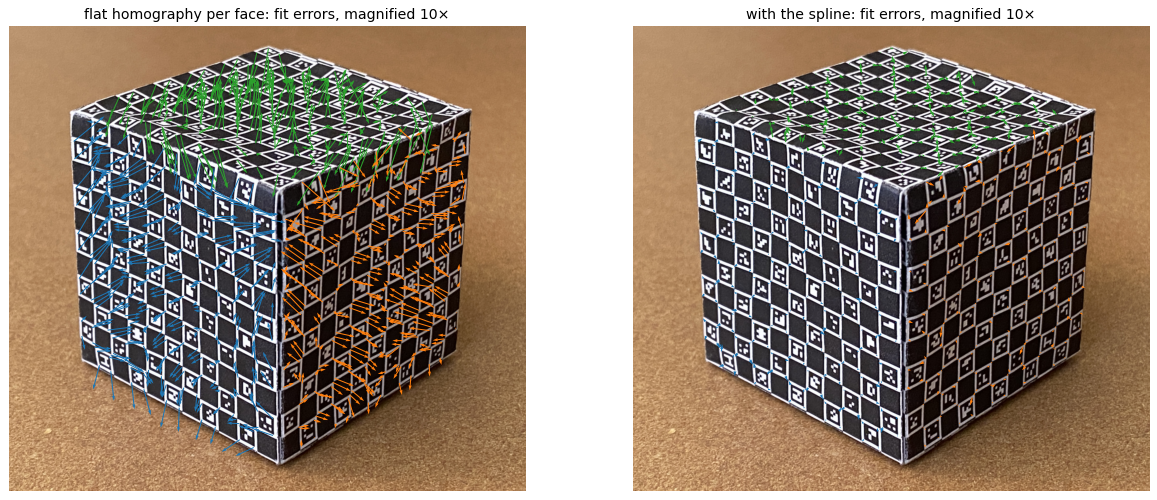

In [4]:
faces = pm.fit_faces(photo, markers, board, faces, smoothing=SMOOTHING)

print("error in photo pixels, rms / worst")
print(f"{'':10}" + "".join(f"{n:>28}" for n in faces))
for smoothing, label in [(None, "flat"), (3000, "s = 3000"), (300, "s = 300"), (30, "s = 30"), (3, "s = 3"), (0, "s = 0")]:
    row = f"{label:10}"
    for f in faces.values():
        h = pm.holdout_px(f["P"], f["Q"], smoothing)
        r = pm.rim_px(f["P"], f["Q"], f["box"], smoothing)
        row += f"  held {h[0]:4.1f}/{h[1]:3.0f} rim {r[0]:4.1f}/{r[1]:3.0f}"
    print(row)

print()
for name, f in faces.items():
    scale = pm._px_per_mm(f["warp"]["H"], board, f["ids"])
    h = pm.holdout_px(f["P"], f["Q"], SMOOTHING)[0]
    r = pm.rim_px(f["P"], f["Q"], f["box"], SMOOTHING)[0]
    print(f"{name:5}: {len(f['P'])} points ({f['corners_found']:.0%} of its corners found), {scale:.0f} px/mm, "
          f"so held out {h / scale:.2f} mm, rim {r / scale:.2f} mm")

view, s = small(photo)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, smoothing, title in zip(axes, [None, SMOOTHING], ["flat homography per face", "with the spline"]):
    ax.imshow(view)
    for name, f in faces.items():
        q = pm.apply_warp(pm.fit_warp(f["P"], f["Q"], smoothing), f["P"])
        ax.quiver(f["Q"][:, 0] * s, f["Q"][:, 1] * s, (q - f["Q"])[:, 0], -(q - f["Q"])[:, 1], color=COLORS[name],
                  angles="uv", scale_units="xy", scale=1 / (10 * s), width=0.002)
    ax.set_title(f"{title}: fit errors, magnified 10×")
    ax.set_xlim(750 * s, 3300 * s); ax.set_ylim(3000 * s, 700 * s); ax.axis("off")
fig.tight_layout(); plt.show()

The table is the reason for a smoothing of 30. On held-out points it's about 3× to 4× better than flat, and from 30 down to 3 nothing much changes, so the exact value isn't delicate. With no smoothing at all, the top face starts getting worse.

Held-out accuracy is about 0.1 to 0.3 mm on the paper. The rim is worse, about 0.3 to 0.6 mm, and that test is harsher than the real fit, which does use the rim points.

## 4. Check against the photo itself

Those numbers only use the markers and corners. The pixels are a separate test: flatten each face back to a square using its map, and compare with the board as printed. If the map is right, the two should line up square for square. The middle row checks them directly, with brightness evened out: gray where they agree, red and cyan fringes where they don't.

top  : correlation 0.76
left : correlation 0.96
right: correlation 0.91


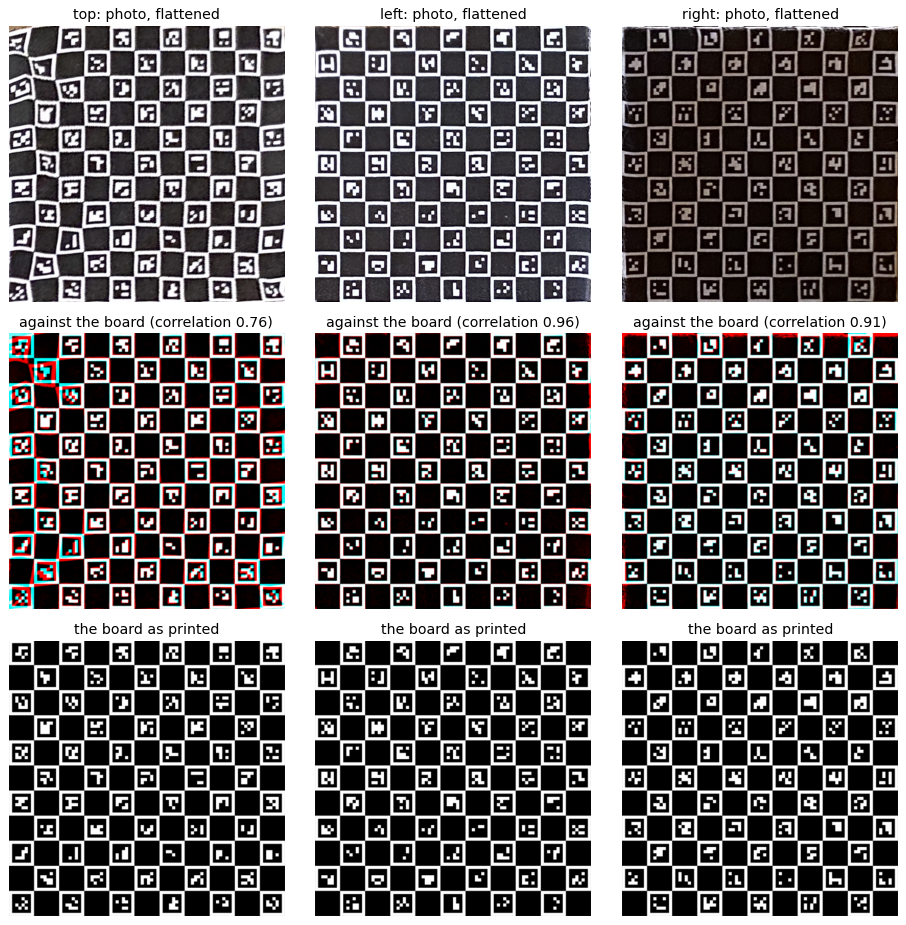

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for col, (name, f) in zip(axes.T, faces.items()):
    flat, xy = pm.rectified_face(photo, f, px_mm=10)
    gray = cv2.GaussianBlur(flat.mean(-1), (0, 0), 0.7)
    pred = pm.sample_board(board, xy)
    ncc = np.corrcoef(gray.ravel(), pred.ravel())[0, 1]
    white, black = np.median(gray[pred > 0.5]), np.median(gray[pred <= 0.5])
    norm = (gray - black) / (white - black)
    col[0].imshow(np.clip(flat, 0, 1)); col[0].set_title(f"{name}: photo, flattened")
    col[1].imshow(np.clip(np.stack([norm, pred, pred], -1), 0, 1)); col[1].set_title(f"against the board (correlation {ncc:.2f})")
    col[2].imshow(pred, cmap="gray"); col[2].set_title("the board as printed")
    print(f"{name:5}: correlation {ncc:.2f}")
    for ax in col:
        ax.axis("off")
fig.tight_layout(); plt.show()

The left and right faces line up square for square, right to the edges. The right face looks dim only because it was in shadow.

The top face is the weak one, and there are two reasons. It's tilted about 67° from the camera (section 8), so it has the fewest pixels per millimeter in one direction. It also has a real dent, visible as the wobble at the upper left of its flattened image, which the spline follows only partly. That spot lands near the cube's far-left corner, on the portrait's yellow background, so it should matter little.

## 5. The canvas

Since the faces are squares, the canvas is just their three outlines, carried into the photo by the maps, so no magenta is needed.

The close-ups show the limits of treating paper as a perfect square. The edges are rounded, and down the front edge the two faces don't quite meet, with a real groove about 1.5 mm wide where the hidden quadrant tucks in. Paper beyond the square outline can still be visible there, which is why the print will continue the picture past each edge (the bleed).

top   says the corner is at [2092. 1500.]
left  says the corner is at [2069. 1513.]
right says the corner is at [2094. 1504.]


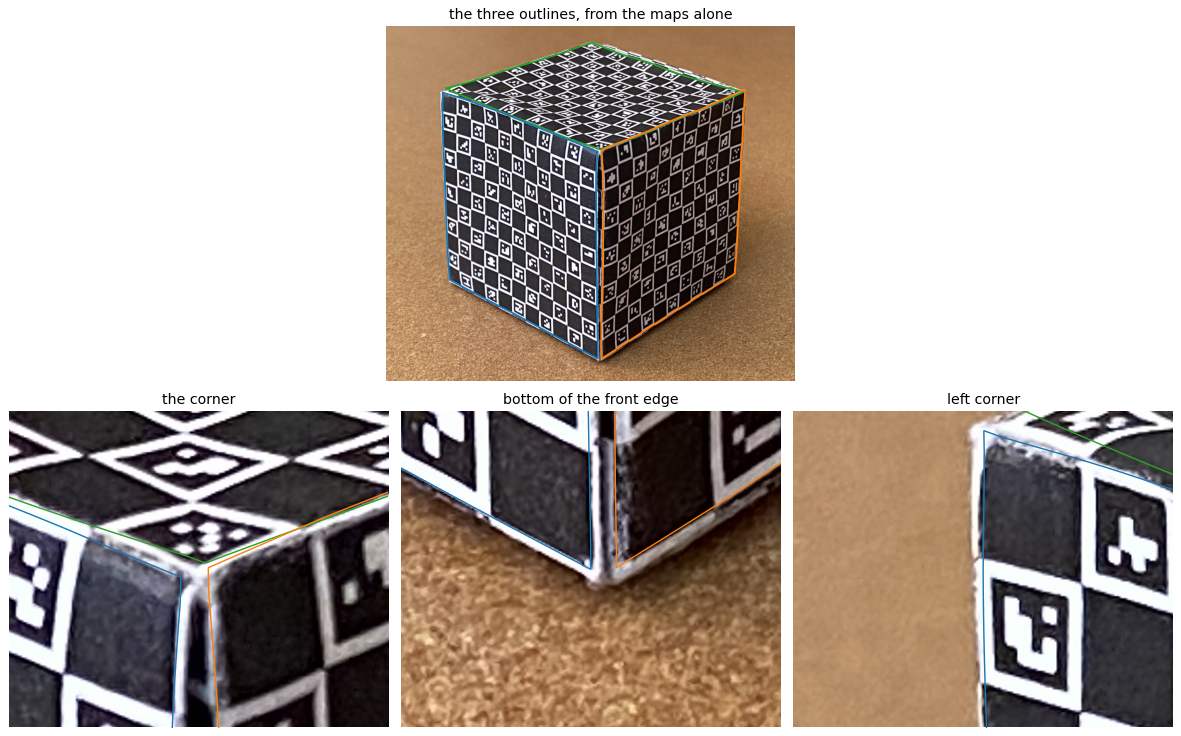

In [6]:
outlines = {n: pm.face_outline(f) for n, f in faces.items()}
view, s = small(photo)
fig = plt.figure(figsize=(14, 9))
ax = fig.add_subplot(2, 3, (1, 3))
ax.imshow(view)
for n, o in outlines.items():
    ax.add_patch(plt.Polygon(o * s, fill=False, ec=COLORS[n], lw=1.5))
ax.set_xlim(700 * s, 3350 * s); ax.set_ylim(3000 * s, 700 * s); ax.axis("off")
ax.set_title("the three outlines, from the maps alone")
hexagon = np.concatenate(list(outlines.values()))
y_point = np.mean([pm.apply_warp(f["warp"], np.array([[100.0, 100.0]]))[0] for f in faces.values()], 0)
spots = {"the corner": y_point, "bottom of the front edge": hexagon[hexagon[:, 1].argmax()],
         "left corner": hexagon[hexagon[:, 0].argmin()]}
for i, (title, c) in enumerate(spots.items()):
    a = fig.add_subplot(2, 3, 4 + i)
    a.imshow(photo)
    for n, o in outlines.items():
        a.add_patch(plt.Polygon(o, fill=False, ec=COLORS[n], lw=1.2))
    a.set_xlim(c[0] - 180, c[0] + 180); a.set_ylim(c[1] + 150, c[1] - 150); a.axis("off"); a.set_title(title)
fig.tight_layout(); plt.show()
for n, f in faces.items():
    print(f"{n:5} says the corner is at", pm.apply_warp(f["warp"], np.array([[100.0, 100.0]]))[0].round(0))

## 6. Lay the picture over the cube, and compute the sheet

The picture is upright in the photo and scaled to cover the bounding box of the three faces, so the whole canvas has picture on it. A hexagon inside a square leaves the square's corners off the cube, which crops his name in the top left and top right.

Then the core step, which works backward from the sheet. **For every point of a face's square, find where it lands in the photo, and paint it the picture's color at that spot.** Fold the sheet the same way, stand in the same place, and those colors line up into the picture.

Going sheet → photo, rather than photo → sheet, means every sheet point gets exactly one color, with no holes.

The result is a stretched, skewed L on the sheet. The top face is smeared the most, since it's the most tilted. The picture also continues 4 mm past each edge. That paper goes around a corner out of sight, and if a fold lands a little off, you see more picture rather than white paper.

picture: 2049 px square in the photo, so one picture pixel is 8.2 photo pixels


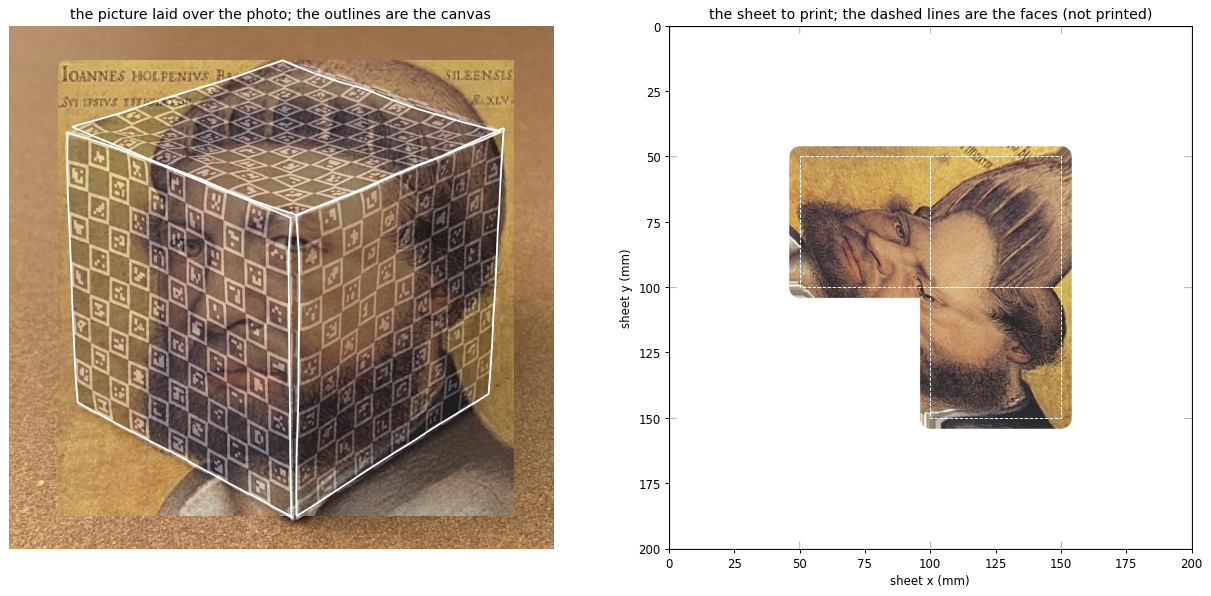

In [7]:
left, top, scale = pm.picture_frame(picture, faces)
print(f"picture: {picture.shape[1] * scale:.0f} px square in the photo, so one picture pixel is {scale:.1f} photo pixels")

sheet, printed, frame = pm.project_onto_faces(picture, faces, board, bleed_mm=BLEED_MM)
final = pm.add_fold_ticks(sheet, faces, board)

view, s = small(photo)
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
axes[0].imshow(view)
extent = [left * s, (left + picture.shape[1] * scale) * s, (top + picture.shape[0] * scale) * s, top * s]
axes[0].imshow(picture, extent=extent, alpha=0.62)
for n, o in outlines.items():
    axes[0].add_patch(plt.Polygon(o * s, fill=False, ec="white", lw=1.5))
axes[0].set_xlim(800 * s, 3250 * s); axes[0].set_ylim(3000 * s, 650 * s); axes[0].axis("off")
axes[0].set_title("the picture laid over the photo; the outlines are the canvas")
axes[1].imshow(final, extent=[0, 200, 200, 0])
axes[1].add_patch(plt.Rectangle((0, 0), 200, 200, fill=False, ec="k"))
for n, f in faces.items():
    x0, y0, side = f["box"]
    axes[1].add_patch(plt.Rectangle((x0, y0), side, side, fill=False, ec="white", lw=0.8, ls="--"))
axes[1].set_title("the sheet to print; the dashed lines are the faces (not printed)")
axes[1].set_xlabel("sheet x (mm)"); axes[1].set_ylabel("sheet y (mm)")
fig.tight_layout(); plt.show()

## 7. Check the result

**First check: fold the sheet back with the measured maps.** This shows what the camera should see if the print folds exactly like the board. It's on the left below, with no lighting, which only shows the geometry.

The middle version keeps each face's brightness as measured in the photo. This one matters: in this photo's light, the right face is much dimmer, and ink can only darken paper. So the portrait will show a tone break down the front edge, unless the light is more even when you view it.

**Second check: an ideal cube.** The right image folds the sheet onto a mathematically perfect cube seen by a pinhole camera, using only the camera's position, not the bowed maps. It's independent enough to catch mirroring and placement errors. Its portrait also comes out whole, even though the sheet was computed for bowed paper.

Neither check is a real test. **Only folding a print and photographing it can show how well the fold repeats.**

how bright white paper is on each face: {'top': 1.0, 'left': 0.99, 'right': 0.63} (1 means overexposed, so the real gap may be larger)
round trip, sheet back to the picture: mean color error 0.009 on a 0 to 1 scale


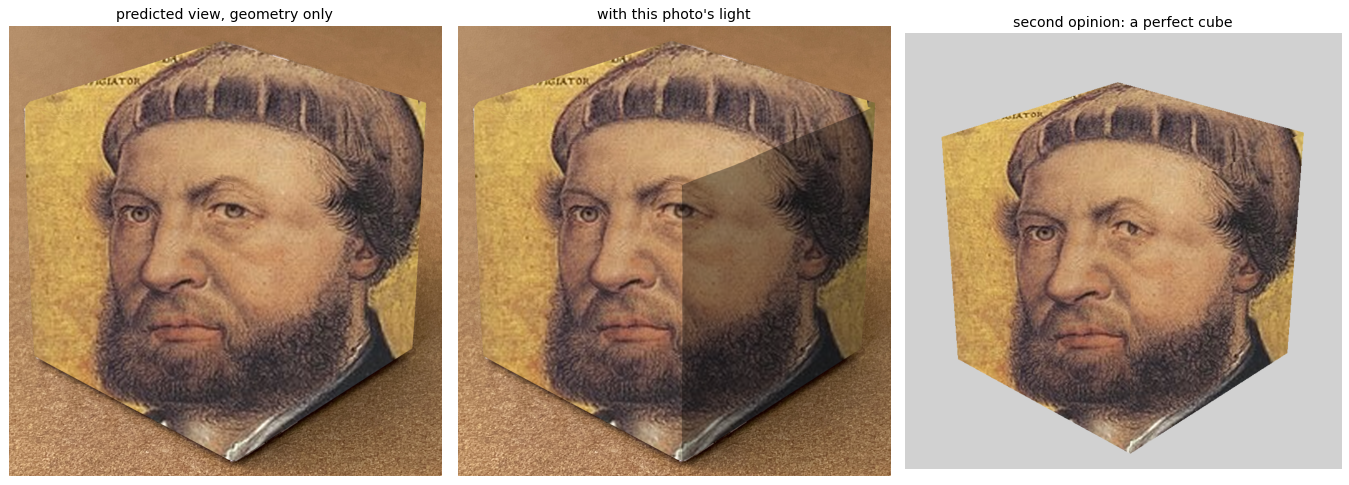

In [8]:
camera = pm.cube_camera(faces, FOCAL_35MM, photo.shape)
levels = pm.white_levels(photo, faces)
print("how bright white paper is on each face:", {k: round(v, 2) for k, v in levels.items()},
      "(1 means overexposed, so the real gap may be larger)")
flat_view, cube = pm.faces_view(photo, sheet, faces, board, shade=False)
lit_view, _ = pm.faces_view(photo, sheet, faces, board, shade=True)
ideal = pm.render_cube(sheet, faces, board, camera["position"], camera["K"], size=800, zoom=1.7)
ys, xs = np.nonzero(cube)
crop = (slice(max(ys.min() - 80, 0), ys.max() + 80), slice(max(xs.min() - 80, 0), xs.max() + 80))

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
for ax, image, title in zip(axes, [flat_view[crop], lit_view[crop], ideal],
                            ["predicted view, geometry only", "with this photo's light", "second opinion: a perfect cube"]):
    ax.imshow(np.clip(image, 0, 1)); ax.set_title(title); ax.axis("off")
fig.tight_layout(); plt.show()

inside = cube & (flat_view.sum(-1) > 0)
frame_x = ((np.arange(photo.shape[1]) + 0.5 - left) / scale - 0.5).astype(np.float32)
frame_y = ((np.arange(photo.shape[0]) + 0.5 - top) / scale - 0.5).astype(np.float32)
mx, my = np.meshgrid(frame_x, frame_y)
target = cv2.remap(picture, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
print(f"round trip, sheet back to the picture: mean color error {np.abs(flat_view - target)[inside].mean():.3f} on a 0 to 1 scale")

## 8. Where to look from

An anamorphosis only works from one place, so here's that place. The ideal cube's fit also gives the camera's position. With the lens at its stated focal length the camera was **about 18 cm from the corner**, which is close. The focal length isn't known exactly and changes the answer: fits with other values stay nearly as good, so treat it as 18 to 22 cm.

The views below show how forgiving it is. These are renders of the perfect cube, moved around from the spot the sheet was computed for.

camera, measured from the corner: 18 cm away, 12 cm above the table
each face's tilt from the line of sight: {'top': '67 deg', 'left': '47 deg', 'right': '51 deg'}
  if the lens were 40 mm: 14 cm away, ideal cube misses the paper by 22.4 px rms
  if the lens were 51 mm: 18 cm away, ideal cube misses the paper by 18.4 px rms
  if the lens were 60 mm: 22 cm away, ideal cube misses the paper by 17.9 px rms


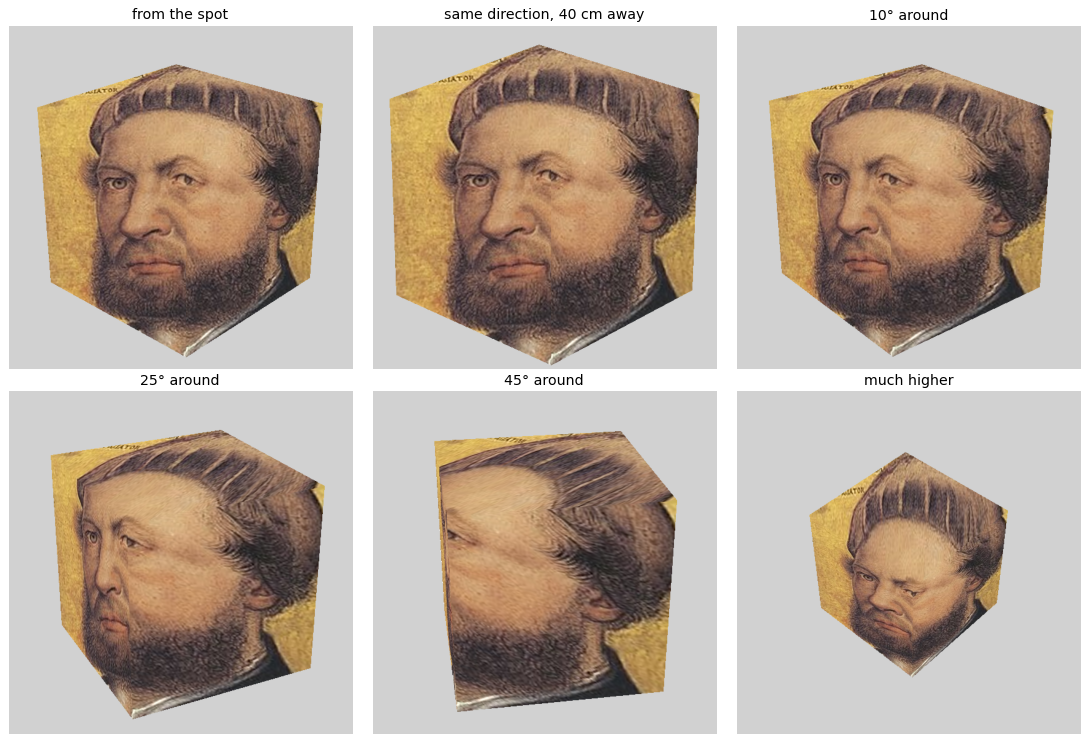

In [9]:
P = camera["position"]
print(f"camera, measured from the corner: {camera['distance'] / 10:.0f} cm away, {camera['height'] / 10:.0f} cm above the table")
print("each face's tilt from the line of sight:", {k: f"{v:.0f} deg" for k, v in camera["tilt"].items()})
for f35 in (40, 51, 60):
    c = pm.cube_camera(faces, f35, photo.shape)
    print(f"  if the lens were {f35} mm: {c['distance'] / 10:.0f} cm away, ideal cube misses the paper by {c['rms']:.1f} px rms")

def turned(p, degrees, up=0.0):
    a = np.radians(degrees)
    x, y = p[0] * np.cos(a) - p[1] * np.sin(a), p[0] * np.sin(a) + p[1] * np.cos(a)
    return np.array([x, y, p[2] + up])

K = camera["K"]
views = {"from the spot": (P, 1.7), "same direction, 40 cm away": (P * 40 / (camera["distance"] / 10), 1.7 * 40 / (camera["distance"] / 10)),
         "10° around": (turned(P, 10), 1.7), "25° around": (turned(P, 25), 1.7), "45° around": (turned(P, 45), 1.7),
         "much higher": (turned(P, 0, 110), 1.5)}
fig, axes = plt.subplots(2, 3, figsize=(13, 8.8))
for ax, (title, (where, zoom)) in zip(axes.ravel(), views.items()):
    ax.imshow(np.clip(pm.render_cube(sheet, faces, board, where, K, size=560, zoom=zoom), 0, 1))
    ax.set_title(title); ax.axis("off")
fig.tight_layout(); plt.show()

Going farther away in the same direction changes little, so the direction matters more than the distance. Moving 10° around barely shows. By 25° the face is visibly skewed and bending at the edges, and by 45° it's no longer readable as a face, which is the effect you want.

## 9. Print

An A4 PDF, in the same layout as the board: the 200 mm sheet inside a black cut line, with hatched waste around it. The small gray ticks on the rim mark the 50, 100 and 150 mm lines, as a folding guide. **Print at 100%, not "fit to page"**, and check the 100 mm bar with a ruler.

saved prints/cube_holbein_a4.pdf (2480, 3508)


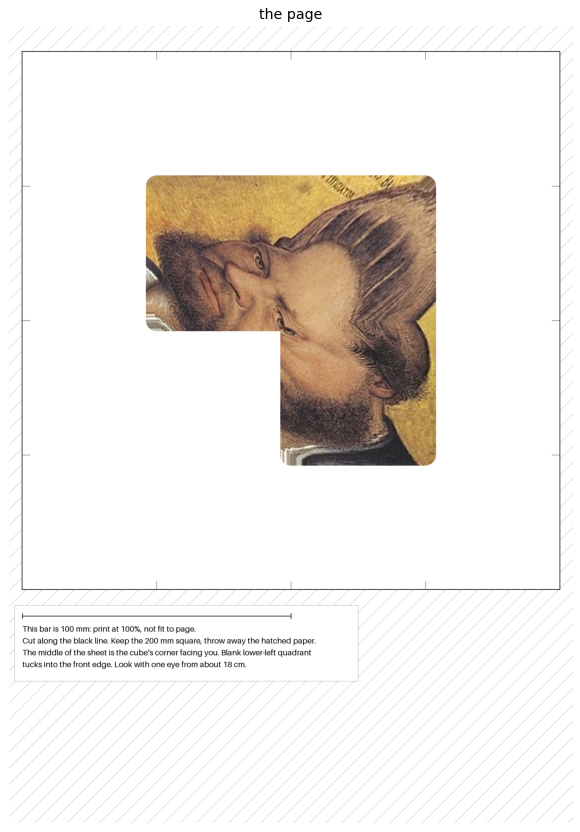

In [10]:
note = ("The middle of the sheet is the cube's corner facing you. Blank lower-left quadrant\n"
        f"tucks into the front edge. Look with one eye from about {camera['distance'] / 10:.0f} cm.")
page = pm.save_print(final, OUTPUT, board, note=note)
print("saved", OUTPUT, page.size)
fig, ax = plt.subplots(figsize=(7, 9.9))
ax.imshow(page); ax.axis("off"); ax.set_title("the page"); fig.tight_layout(); plt.show()

## Folding and viewing

1. Print on the same paper as the board, printed side out, and cut along the black line.
2. Fold the same cube the same way, with the print facing out. The middle of the L, the sheet's center, has to become the corner at the top front. The blank lower-left quadrant goes where the board's did, into the groove down the front edge. The print has no markers, so if the top face isn't the upper-right square of the L, turn the sheet.
3. Sit the cube on a table and look along the same direction as the photo, with one eye, about 18 cm from the corner and 12 cm above the table. A phone camera is easier than an eye: close focus and one lens.
4. Light it so the three faces are about equally bright, since the right face was much dimmer in this photo.

## What this doesn't know yet

- **Whether a second fold matches the first.** The maps describe the board's cube, including its bow. Only a real fold can show how much of that repeats. Bow that doesn't repeat will show up as errors of about the size the flat fit missed: under a millimeter on average, up to about 2 mm at worst.
- **How good it looks on paper.** The picture is only 250 × 250 pixels, each about 8 photo pixels here, so it's soft.